# **Aprendizado de Máquina Aplicado à Problemas - SME0860**
## Grupo:
### Leonardo Demore - 15674786
### Arthur Araujo - 14651458
### Arthur Filliettaz - 12532055

## Conjunto de Dados: **IEXO - Intoxicação Exógena**

# Parte 1: Exploração e Análise de Dados + <br>Pré-Processamento

## Baixando o conjunto de dados:

### Imports

In [1]:
from pysus.online_data import SINAN
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import gdown

### Usando o pysus para baixar o conjunto; também subimos este conjunto para uma hospedagem externa, para facilitar os próximos downloads 

In [2]:
# Download dos dados pelo pysus (rodar se necesśario)
AGRAVO = 'IEXO'
ANOS = [2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023] 

try:
    arquivos = SINAN.download(AGRAVO, years=ANOS)
    
    # Concatena tudo em um único dataframe
    df = pd.concat([arq.to_dataframe() for arq in arquivos], ignore_index=True)

    print(f"Sucesso! Dataset carregado com {df.shape[0]} linhas e {df.shape[1]} colunas.")
    
except Exception as e:
    print(f"Ocorreu um erro: {e}")

df.to_csv("raw_data.csv")

IEXOBR20.parquet: : 19.2MB [00:07, 2.46MB/s]                      


Sucesso! Dataset carregado com 1616088 linhas e 82 colunas.


### Carregando os dados

In [5]:
# Baixando o Dataset (rodar se necessário)
FILE_ID = "1SqHCiToyoIw4JhkhJzIkl5jL83erbE_-"
OUTPUT = "raw_data.csv"

url = f"https://drive.google.com/uc?id={FILE_ID}"
gdown.download(url, OUTPUT, quiet=False)
df = pd.read_csv(OUTPUT)

Downloading...
From (original): https://drive.google.com/uc?id=1SqHCiToyoIw4JhkhJzIkl5jL83erbE_-
From (redirected): https://drive.google.com/uc?id=1SqHCiToyoIw4JhkhJzIkl5jL83erbE_-&confirm=t&uuid=c6a0fd1f-4b3b-4404-81c3-554fc79729be
To: /home/leodemore/GitHub/amap/raw_data.csv
100%|██████████| 242M/242M [00:06<00:00, 36.8MB/s] 
/tmp/ipykernel_7806/193718925.py:7: DtypeWarning: Columns (23,42,43,50,56,58) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(OUTPUT)


## Começando a exploração:


In [3]:
df = pd.read_csv("raw_data.csv")

# "Cara" do dataframe
display(df.head())

# Mostra as colunas, um resumo estatístico e nulos 
df.info()

/tmp/ipykernel_17299/3275252087.py:1: DtypeWarning: Columns (4,11,23,42,43,50,56) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("raw_data.csv")


,Unnamed: 0,TP_NOT,ID_AGRAVO,DT_NOTIFIC,SEM_NOT,NU_ANO,SG_UF_NOT,ID_MUNICIP,ID_REGIONA,ID_UNIDADE,...,TRAB_DESC,LOC_EXP_DE,OUT_AGENTE,UTIL_DESC,LAVOURA,CIRCUN_DES,NU_LOTE_I,INTOX_CHUM,INTOX_MERC,INTOX_META
0,0,2,T659,2013-04-27,201317,2013,52.0,520110,1792.0,2361744.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
1,1,2,T659,2013-04-27,201317,2013,52.0,520110,1792.0,2361744.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
2,2,2,T659,2013-04-27,201317,2013,26.0,261110,1503.0,2430711.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
3,3,2,T659,2013-04-27,201317,2013,31.0,313130,1468.0,2205440.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN
4,4,2,T659,2013-04-27,201317,2013,31.0,311460,1466.0,2764059.0,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1616088 entries, 0 to 1616087
Data columns (total 83 columns):
 #   Column      Non-Null Count    Dtype  
---  ------      --------------    -----  
 0   Unnamed: 0  1616088 non-null  int64  
 1   TP_NOT      1616088 non-null  int64  
 2   ID_AGRAVO   1616088 non-null  object 
 3   DT_NOTIFIC  1616088 non-null  object 
 4   SEM_NOT     1616088 non-null  object 
 5   NU_ANO      1616088 non-null  int64  
 6   SG_UF_NOT   1616087 non-null  float64
 7   ID_MUNICIP  1616088 non-null  int64  
 8   ID_REGIONA  1487881 non-null  float64
 9   ID_UNIDADE  1616087 non-null  float64
 10  DT_SIN_PRI  1616088 non-null  object 
 11  SEM_PRI     1616088 non-null  object 
 12  ANO_NASC    1583092 non-null  float64
 13  NU_IDADE_N  1616088 non-null  int64  
 14  CS_SEXO     1616088 non-null  object 
 15  CS_GESTANT  1616061 non-null  float64
 16  CS_RACA     1588092 non-null  float64
 17  CS_ESCOL_N  1493395 non-null  float64
 18  SG_UF       1615906 no

### Nossos dados possuem 83 colunas; a maioria não servirá para nossa análise, então vamos manter aquelas que julgamos ser relevantes de alguma forma

### Escolhendo Quais colunas vamos manter na análise

In [4]:
columns = [
    'DT_NOTIFIC', 'ID_OCUPA_N', 'SIT_TRAB', 'LOC_EXPO', 'ID_MUNICIP','UF_EMP', 'MUN_EMP',
    'AGENTE_TOX', 'VIA_1', 'CIRCUNSTAN',
    'DOENCA_TRA', 'TPEXP', 'NUTEMPO', 'TPTEMPO', 'TPATENDE', 'HOSPITAL',
    'DTINTERNA', 'CLASSI_FIN', 'EVOLUCAO',
    'DT_OBITO', 'NU_IDADE_N', 'CS_SEXO', 'CS_GESTANT',
    'CS_RACA', 'CS_ESCOL_N'
]

# Verifica se alguma coluna escolhida para manter não existe
present_columns = [c for c in columns if c in df.columns]
missing_columns = [c for c in columns if c not in df.columns]

print(f"Colunas da lista que não existem no dataset: {missing_columns}")

# mantém apenas as colunas relevantes
df = df[present_columns].copy()

# Prints para avaliação
print(f"DataFrame filtrado: {df.shape[0]} linhas x {df.shape[1]} colunas")
display(df.head(5))

Colunas da lista que não existem no dataset: []
DataFrame filtrado: 1616088 linhas x 25 colunas


,DT_NOTIFIC,ID_OCUPA_N,SIT_TRAB,LOC_EXPO,ID_MUNICIP,UF_EMP,MUN_EMP,AGENTE_TOX,VIA_1,CIRCUNSTAN,...,HOSPITAL,DTINTERNA,CLASSI_FIN,EVOLUCAO,DT_OBITO,NU_IDADE_N,CS_SEXO,CS_GESTANT,CS_RACA,CS_ESCOL_N
0,2013-04-27,999991.0,NaN,1.0,520110,52.0,520110.0,NaN,1.0,9.0,...,2.0,NaN,1.0,1.0,NaN,4007,M,6.0,4.0,1.0
1,2013-04-27,NaN,NaN,1.0,520110,52.0,520110.0,1.0,1.0,2.0,...,2.0,NaN,1.0,1.0,NaN,4003,F,6.0,1.0,10.0
2,2013-04-27,999994.0,99.0,1.0,261110,26.0,261110.0,7.0,1.0,2.0,...,2.0,NaN,2.0,1.0,NaN,4002,F,6.0,4.0,10.0
3,2013-04-27,NaN,NaN,NaN,313130,NaN,NaN,11.0,1.0,8.0,...,2.0,NaN,1.0,1.0,NaN,4038,M,6.0,1.0,9.0
4,2013-04-27,NaN,NaN,1.0,311460,31.0,311460.0,1.0,1.0,2.0,...,2.0,NaN,1.0,1.0,NaN,4004,M,6.0,1.0,10.0


### Aplicando pré-processamento para poder explorar os dados: criando um dicionário para mapear algumas variáveis numéricas em rótulos que conseguimos entender

In [5]:
# Dicionário das principais variaveis (facilita o entendimento dos dados)
dictionary = {
'CS_SEXO': {'M': 'Masculino', 'F': 'Feminino', 'I': 'Ignorado'},

'CS_GESTANT': {
    1.0: '1º Trimestre', 2.0: '2º Trimestre', 3.0: '3º Trimestre',
    4.0: 'Idade Gest. Ignorada', 5.0: 'Não', 6.0: 'Não se aplica', 9.0: 'Ignorado'
},

'CS_RACA': {
    1.0: 'Branca', 2.0: 'Preta', 3.0: 'Amarela',
    4.0: 'Parda', 5.0: 'Indígena', 9.0: 'Ignorado'
},

'CS_ESCOL_N': {
    0.0: 'Analfabeto', 1.0: '1ª-4ª série incompleta', 2.0: '4ª série completa',
    3.0: '5ª-8ª série incompleta', 4.0: 'Fundamental completo', 5.0: 'Médio incompleto',
    6.0: 'Médio completo', 7.0: 'Superior incompleto', 8.0: 'Superior completo',
    9.0: 'Não se aplica', 10.0: 'Ignorado'
},

'LOC_EXPO': {
    1.0: 'Residência', 2.0: 'Habitação coletiva', 3.0: 'Creche',
    4.0: 'Instituição de ensino', 5.0: 'Trabalho', 6.0: 'Unidade de saúde',
    7.0: 'Via pública', 8.0: 'Outros', 9.0: 'Ignorado'
},

'AGENTE_TOX': {
    1.0: 'Medicamento', 2.0: 'Agrotóxico (Uso Agrícola)', 3.0: 'Agrotóxico (Uso Doméstico)',
    4.0: 'Agrotóxico (Saúde Pública)', 5.0: 'Raticida', 6.0: 'Produto veterinário',
    7.0: 'Domissanitário', 8.0: 'Cosmético', 9.0: 'Produto químico industrial',
    10.0: 'Metal', 11.0: 'Droga de abuso', 12.0: 'Planta', 13.0: 'Alimento',
    14.0: 'Outro', 99.0: 'Ignorado'
},

'VIA_1': {
    1.0: 'Digestiva', 2.0: 'Respiratória', 3.0: 'Cutânea',
    4.0: 'Ocular', 5.0: 'Parenteral', 6.0: 'Outras',
    7.0: 'Placentária', 9.0: 'Ignorado'
},

'CIRCUNSTAN': {
    1.0: 'Uso habitual', 2.0: 'Acidental', 3.0: 'Ambiental',
    4.0: 'Uso terapêutico', 5.0: 'Prescrição médica inadequada', 6.0: 'Erro de administração',
    7.0: 'Automedicação', 8.0: 'Abuso', 9.0: 'Ingestão de alimento',
    10.0: 'Tentativa de suicídio', 11.0: 'Violência / Homicídio', 12.0: 'Uso ocupacional',
    13.0: 'Outra', 99.0: 'Ignorado'
},

'TPEXP': {1.0: 'Aguda-única', 2.0: 'Aguda-repetida', 3.0: 'Crônica', 9.0: 'Ignorado'},

'SIT_TRAB': {
        1.0: 'Empregado com carteira', 
        2.0: 'Empregado sem carteira', 
        3.0: 'Autônomo/conta própria',
        4.0: 'Servidor público estatutário', 
        5.0: 'Servidor público celetista', 
        6.0: 'Aposentado',
        7.0: 'Desempregado', 
        8.0: 'Trabalho temporário', 
        9.0: 'Cooperativado', 
        10.0: 'Trabalhador avulso',
        11.0: 'Empregador', 
        12.0: 'Outros', 
        99.0: 'Ignorado'
    },

'CLASSI_FIN': {
    1.0: 'Confirmado', 2.0: 'Exposição', 3.0: 'Reação Adversa',
    4.0: 'Diagnóstico Diferencial', 5.0: 'Descartado'
},

'EVOLUCAO': {
    1.0: 'Cura sem sequela',
    2.0: 'Cura com sequela',
    3.0: 'Óbito por Intoxicação Exógena',
    4.0: 'Óbito por outras causas',
    5.0: 'Perda de seguimento',
    9.0: 'Ignorado'
}}

### Aplicando todo o pré-processamento: 
### converte colunas que deveriam ser numéricas (muitas vêm como 'object'); também trata erros de digitação
### Padroniza outliers na coluna 'gravidez'
### Usa o dicionário definido acima para criar colunas vizinhas com a descrição do que o número representa
### Converte colunas que deveriam ser data
### Padroniza as idades

In [ ]:
# Cria uma cópia para não alterar o df diretamente
df_raw = df.copy()

# Lista das colunas que precisam ser lidas como número
obj_to_numeric = [
    'SIT_TRAB', 'LOC_EXPO', 'UF_EMP', 'MUN_EMP', 'AGENTE_TOX',
    'UTILIZACAO', 'VIA_1', 'CIRCUNSTAN', 'DOENCA_TRA', 'TPEXP',
    'TPTEMPO', 'TPATENDE', 'HOSPITAL', 'CLASSI_FIN', 'EVOLUCAO',
    'CS_GESTANT', 'CS_RACA', 'CS_ESCOL_N'
]

# Converte para número de fato
for col in obj_to_numeric:
    if col in df_raw.columns:
        df_raw[col] = pd.to_numeric(df_raw[col], errors='coerce')

# Padroniza outliers (homens com gravidez != de "não se aplica")
if 'CS_SEXO' in df_raw.columns and 'CS_GESTANT' in df_raw.columns:
    df_raw.loc[(df_raw['CS_SEXO'] == 'M') & (df_raw['CS_GESTANT'].isin([5.0, 9.0])), 'CS_GESTANT'] = 6.0

# Cria uma nova coluna com a descrição da coluna numérica 
for col, mapping in dictionary.items():
    if col in df_raw.columns:
        df_raw[f"{col}_DESC"] = df_raw[col].map(mapping)

# Converte datas para o formato correto
for col in ['DT_NOTIFIC', 'DTINTERNA', 'DT_OBITO']:
    if col in df_raw.columns:
        df_raw[col] = pd.to_datetime(df_raw[col], errors='coerce')

# Convertendo as idades para formato legível
def decode_idade(x):
    try:
        s = str(int(x)).zfill(4)
        unid, val = s[0], int(s[1:])
        if unid == '4': return val
        if unid == '3': return val / 12
        if unid == '2': return val / 365
        return np.nan
    except: 
        return np.nan

if 'NU_IDADE_N' in df_raw.columns:
    df_raw['IDADE_ANOS'] = df_raw['NU_IDADE_N'].apply(decode_idade)
    
    # Tratando os outliers de idade
    df_raw.loc[df_raw['IDADE_ANOS'] > 110, 'IDADE_ANOS'] = np.nan

if 'NUTEMPO' in df_raw.columns:
    df_raw['NUTEMPO'] = df_raw['NUTEMPO'].astype(str).str.extract(r'(\d+)').astype(float)

display(df_raw)


,DT_NOTIFIC,ID_OCUPA_N,SIT_TRAB,LOC_EXPO,ID_MUNICIP,UF_EMP,MUN_EMP,AGENTE_TOX,VIA_1,CIRCUNSTAN,...,CS_ESCOL_N_DESC,LOC_EXPO_DESC,AGENTE_TOX_DESC,VIA_1_DESC,CIRCUNSTAN_DESC,TPEXP_DESC,SIT_TRAB_DESC,CLASSI_FIN_DESC,EVOLUCAO_DESC,IDADE_ANOS
0,2013-04-27,999991.0,NaN,1.0,520110,52.0,520110.0,NaN,1.0,9.0,...,1ª-4ª série incompleta,Residência,NaN,Digestiva,Ingestão de alimento,Aguda-única,NaN,Confirmado,Cura sem sequela,7.0
1,2013-04-27,NaN,NaN,1.0,520110,52.0,520110.0,1.0,1.0,2.0,...,Ignorado,Residência,Medicamento,Digestiva,Acidental,Aguda-única,NaN,Confirmado,Cura sem sequela,3.0
2,2013-04-27,999994.0,99.0,1.0,261110,26.0,261110.0,7.0,1.0,2.0,...,Ignorado,Residência,Domissanitário,Digestiva,Acidental,Aguda-única,Ignorado,Exposição,Cura sem sequela,2.0
3,2013-04-27,NaN,NaN,NaN,313130,NaN,NaN,11.0,1.0,8.0,...,Não se aplica,NaN,Droga de abuso,Digestiva,Abuso,Aguda-única,NaN,Confirmado,Cura sem sequela,38.0
4,2013-04-27,NaN,NaN,1.0,311460,31.0,311460.0,1.0,1.0,2.0,...,Ignorado,Residência,Medicamento,Digestiva,Acidental,Aguda-única,NaN,Confirmado,Cura sem sequela,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1616083,2023-10-03,NaN,99.0,1.0,421550,42.0,421550.0,7.0,3.0,1.0,...,Não se aplica,Residência,Domissanitário,Cutânea,Uso habitual,Aguda-única,Ignorado,Exposição,Cura sem sequela,30.0
1616084,2023-10-03,NaN,2.0,1.0,430790,43.0,430790.0,1.0,1.0,10.0,...,Médio completo,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Empregado sem carteira,Confirmado,Cura sem sequela,27.0
1616085,2023-10-03,516110,3.0,1.0,410690,41.0,410690.0,1.0,1.0,10.0,...,Médio completo,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Autônomo/conta própria,Confirmado,Cura sem sequela,35.0
1616086,2023-10-03,999992,12.0,1.0,330420,33.0,330420.0,1.0,1.0,10.0,...,Não se aplica,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Outros,Confirmado,Cura sem sequela,52.0


### Após este processamento, vamos verificar como os nulos se comportam 

In [11]:
# Calcula a porcentagem de nulos por coluna
nan_percentual = (df_raw.isna().sum() / len(df_raw)) * 100

# Filtra apenas as colunas que têm 
# algum nulo (quase todas) e ordena 
nans = nan_percentual[nan_percentual > 0].sort_values(ascending=False)

print("PORCENTAGEM DE NULOS POR COLUNA")
print(nans.round(2).astype(str) + ' %')

PORCENTAGEM DE NULOS POR COLUNA
DT_OBITO            99.0 %
DTINTERNA          71.79 %
ID_OCUPA_N         55.99 %
MUN_EMP            19.44 %
UF_EMP             19.27 %
SIT_TRAB_DESC      14.44 %
SIT_TRAB           14.44 %
TPTEMPO            13.59 %
CLASSI_FIN_DESC    11.53 %
EVOLUCAO_DESC       9.18 %
EVOLUCAO            9.18 %
TPEXP_DESC          9.18 %
CS_ESCOL_N          7.59 %
CS_ESCOL_N_DESC     7.59 %
VIA_1_DESC          7.37 %
TPEXP               7.26 %
AGENTE_TOX          7.12 %
AGENTE_TOX_DESC     7.12 %
VIA_1               7.05 %
LOC_EXPO            5.87 %
LOC_EXPO_DESC       5.87 %
HOSPITAL            5.79 %
DOENCA_TRA          5.18 %
TPATENDE            4.58 %
CIRCUNSTAN_DESC     4.22 %
CIRCUNSTAN          4.22 %
NUTEMPO             3.35 %
CS_RACA_DESC        1.73 %
CS_RACA             1.73 %
CLASSI_FIN          0.93 %
IDADE_ANOS          0.01 %
CS_GESTANT_DESC      0.0 %
CS_GESTANT           0.0 %
dtype: object


### Análise dos nulos: 
- DT_OBITO: Faz sentido ser quase totalmente nula, pois pouquíssimas internações por intoxicação exógena levam a óbito
- DT_INTERNA: Segue uma lógica parecida, a maioria dos casos não requer internação
- ID_OCUPA_N: Muitos NaNs pois esse dado não é levantado com frequência, e o principal motivo é que muitos idosos e crianças não possuem ocupação

Os outros nulos são apenas ruído nos dados

### Mais processamento: vamos transformar a coluna "data de internação" em binária: 1 representa internação e 0 representa não internação. Além disso, vamos dropar instâncias onde nulos não fazem sentido, e preencher outras com "ignorado" para preservar a informação

In [12]:
# Engenharia de Feature com a Data de Internação:
# Vamos transformar a data em uma coluna binária, onde
# 1 indica internação e 0 indica não internado
if 'DTINTERNA' in df_raw.columns:
    df_raw['INTERNADO'] = df_raw['DTINTERNA'].notna().astype(int)
    df_raw = df_raw.drop(columns=['DTINTERNA']) # Remove a original

# Dropa instâncias onde não pode haver nulos 
# Lista com as colunas finais onde os nulos não são aceitáveis
    important = [
        'CS_ESCOL_N_DESC', 'CS_ESCOL_N', 
        'VIA_1_DESC', 'VIA_1', 
        'HOSPITAL', 'TPATENDE', 
        'NUTEMPO', 
        'LOC_EXPO', 'LOC_EXPO_DESC', 
        'DOENCA_TRA', 
        'CIRCUNSTAN_DESC', 'CIRCUNSTAN', 
        'CS_RACA_DESC', 'CS_RACA', 
        'CS_GESTANT_DESC', 'CS_GESTANT',
        'EVOLUCAO', 'EVOLUCAO_DESC',
        'AGENTE_TOX', 'AGENTE_TOX_DESC', 'IDADE_ANOS'
    ]
df_raw = df_raw.dropna(subset=important)

# Preenche o restante "Ignorado" para aproveitar os dados
to_fill = [
    'TPTEMPO', 'SIT_TRAB', 'MUN_EMP', 'UF_EMP', 
    'CLASSI_FIN', 'CLASSI_FIN_DESC', 'TPEXP', 'TPEXP_DESC',
    'SIT_TRAB_DESC'
]

for col in to_fill:
    if col in df_raw.columns:
        # Se for uma coluna de texto 
        if df_raw[col].dtype == 'object':
            df_raw[col] = df_raw[col].fillna('Ignorado')
        # Se for numérica 
        else:
            df_raw[col] = df_raw[col].fillna(99.0)

### Resultado do processamento:

In [13]:
display(df_raw)

# calculando os nulos novamente
nan_percentual = (df_raw.isna().sum() / len(df_raw)) * 100

# Filtra apenas as colunas que têm 
# algum nulo (quase todas) e ordena 
nans = nan_percentual[nan_percentual > 0].sort_values(ascending=False)

print("PORCENTAGEM DE NULOS POR COLUNA")
print(nans.round(2).astype(str) + ' %')


,DT_NOTIFIC,ID_OCUPA_N,SIT_TRAB,LOC_EXPO,ID_MUNICIP,UF_EMP,MUN_EMP,AGENTE_TOX,VIA_1,CIRCUNSTAN,...,LOC_EXPO_DESC,AGENTE_TOX_DESC,VIA_1_DESC,CIRCUNSTAN_DESC,TPEXP_DESC,SIT_TRAB_DESC,CLASSI_FIN_DESC,EVOLUCAO_DESC,IDADE_ANOS,INTERNADO
1,2013-04-27,NaN,99.0,1.0,520110,52.0,520110.0,1.0,1.0,2.0,...,Residência,Medicamento,Digestiva,Acidental,Aguda-única,Ignorado,Confirmado,Cura sem sequela,3.0,0
2,2013-04-27,999994.0,99.0,1.0,261110,26.0,261110.0,7.0,1.0,2.0,...,Residência,Domissanitário,Digestiva,Acidental,Aguda-única,Ignorado,Exposição,Cura sem sequela,2.0,0
4,2013-04-27,NaN,99.0,1.0,311460,31.0,311460.0,1.0,1.0,2.0,...,Residência,Medicamento,Digestiva,Acidental,Aguda-única,Ignorado,Confirmado,Cura sem sequela,4.0,0
5,2013-04-27,NaN,12.0,1.0,520140,52.0,520140.0,7.0,1.0,2.0,...,Residência,Domissanitário,Digestiva,Acidental,Aguda-única,Outros,Exposição,Cura sem sequela,2.0,0
8,2013-04-27,NaN,12.0,1.0,270030,27.0,270030.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Outros,Confirmado,Cura sem sequela,14.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1616083,2023-10-03,NaN,99.0,1.0,421550,42.0,421550.0,7.0,3.0,1.0,...,Residência,Domissanitário,Cutânea,Uso habitual,Aguda-única,Ignorado,Exposição,Cura sem sequela,30.0,0
1616084,2023-10-03,NaN,2.0,1.0,430790,43.0,430790.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Empregado sem carteira,Confirmado,Cura sem sequela,27.0,1
1616085,2023-10-03,516110,3.0,1.0,410690,41.0,410690.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Autônomo/conta própria,Confirmado,Cura sem sequela,35.0,1
1616086,2023-10-03,999992,12.0,1.0,330420,33.0,330420.0,1.0,1.0,10.0,...,Residência,Medicamento,Digestiva,Tentativa de suicídio,Aguda-única,Outros,Confirmado,Cura sem sequela,52.0,1


PORCENTAGEM DE NULOS POR COLUNA
DT_OBITO      98.95 %
ID_OCUPA_N    51.72 %
dtype: object


### Agora os dados estão limpos e podemos começar com a análise gráfica. Vamos salvar o conjunto processado novamente, para facilitar os próximos downloads

In [14]:
df_raw.to_csv("processed_df.csv", index=False)

## Plots e Gráficos

### Baixar o conjunto processado (caso necessário)

In [13]:
# Baixando o Dataset (rodar se necessário)
FILE_ID = "1XO6vC_Fw6n29BXxba-ZPryh7A0wf0egw"
OUTPUT = "processed_data.csv"

url = f"https://drive.google.com/uc?id={FILE_ID}"
gdown.download(url, OUTPUT, quiet=False)

Downloading...
From (original): https://drive.google.com/uc?id=1XO6vC_Fw6n29BXxba-ZPryh7A0wf0egw
From (redirected): https://drive.google.com/uc?id=1XO6vC_Fw6n29BXxba-ZPryh7A0wf0egw&confirm=t&uuid=6054cd42-3d6f-468e-acab-1824fdb59d98
To: /home/leodemore/GitHub/amap/processed_data.csv
100%|██████████| 116M/116M [00:02<00:00, 39.2MB/s] 


'processed_data.csv'

/tmp/ipykernel_17299/1038638054.py:1: DtypeWarning: Columns (1) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("processed_df.csv")


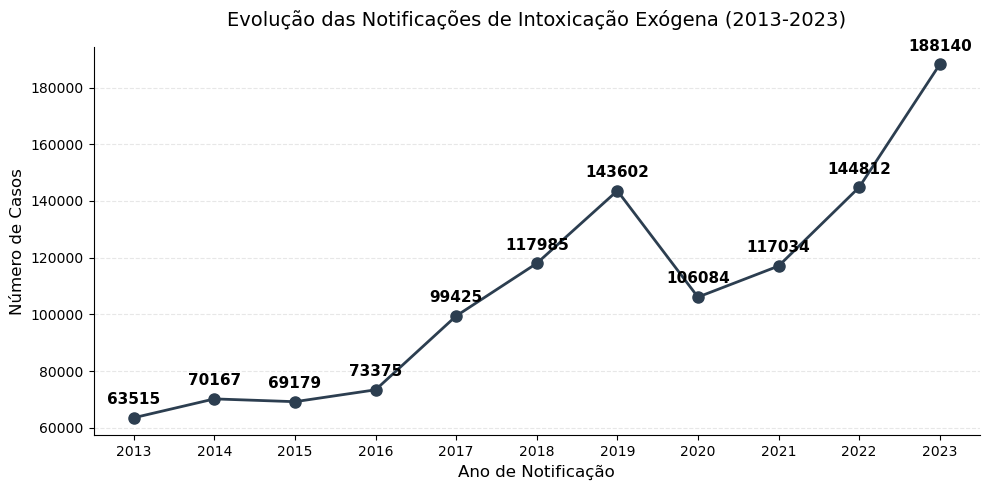

In [23]:
df = pd.read_csv("processed_df.csv")

# Extração da data
df['DT_NOTIFIC'] = pd.to_datetime(df['DT_NOTIFIC'], errors='coerce')
contagem_anos = df['DT_NOTIFIC'].dt.year.value_counts().sort_index()

# Configuração da figura
plt.figure(figsize=(10, 5))
contagem_anos.plot(kind='line', marker='o', color='#2c3e50', lw=2, markersize=8)

# Títulos e rótulos 
plt.title('Evolução das Notificações de Intoxicação Exógena (2013-2023)', fontsize=14, pad=15)
plt.xlabel('Ano de Notificação', fontsize=12)
plt.ylabel('Número de Casos', fontsize=12)

# Força o eixo X a mostrar apenas os anos 
plt.xticks(contagem_anos.index)

# Adiciona os números em cima de cada ponto do gráfico
for ano, valor in zip(contagem_anos.index, contagem_anos.values):
    plt.text(ano, valor + (max(contagem_anos.values) * 0.02), f'{int(valor)}',
             ha='center', va='bottom', fontsize=11, fontweight='bold')

# Estética limpa 
plt.grid(axis='y', alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()

# plt.savefig('evolucao_notific_21_23.png', dpi=300, bbox_inches='tight')

plt.show()

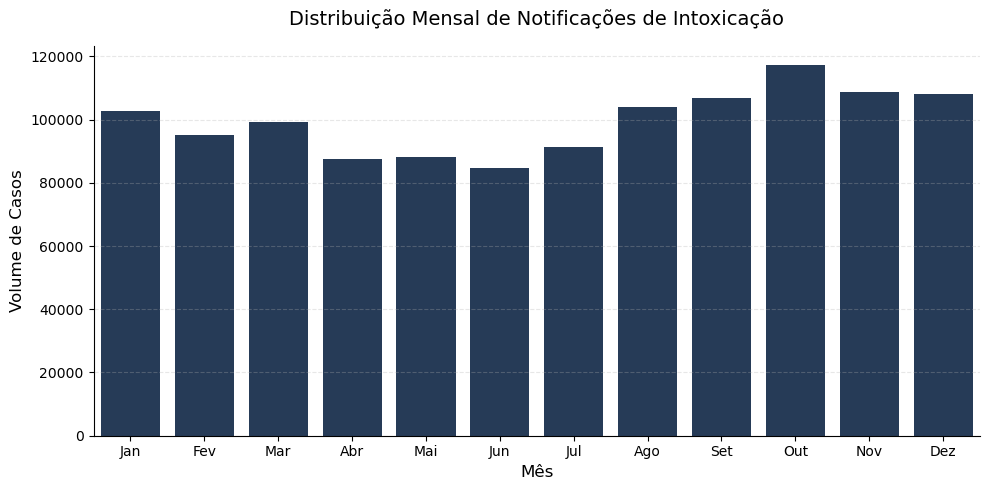

In [24]:
# Criando a coluna auxiliar de Mês
df['Mes'] = df['DT_NOTIFIC'].dt.month

# Configurando o tamanho da figura para 1 único gráfico (mais estreito que o original)
plt.figure(figsize=(10, 5))

# Calculando os casos por mês
casos_mes = df['Mes'].value_counts().sort_index()

# Plotando o gráfico de barras
sns.barplot(
    x=casos_mes.index, 
    y=casos_mes.values, 
    color="#1E3A5F",
    legend=False            
)

# Ajustando títulos e rótulos
plt.title('Distribuição Mensal de Notificações de Intoxicação', fontsize=14, pad=15)
plt.ylabel('Volume de Casos', fontsize=12)
plt.xlabel('Mês', fontsize=12)

# Trocando os números 1 a 12 pelos nomes dos meses formatados
plt.xticks(
    ticks=range(12), 
    labels=['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez']
)

# Deixando a estética mais limpa e profissional
sns.despine()
plt.grid(axis='y', alpha=0.3, linestyle='--')
plt.tight_layout()

# Salvando a imagem com um nome que faz sentido agora
#plt.savefig('sazonalidade_mensal.png', dpi=300, bbox_inches='tight')

plt.show()

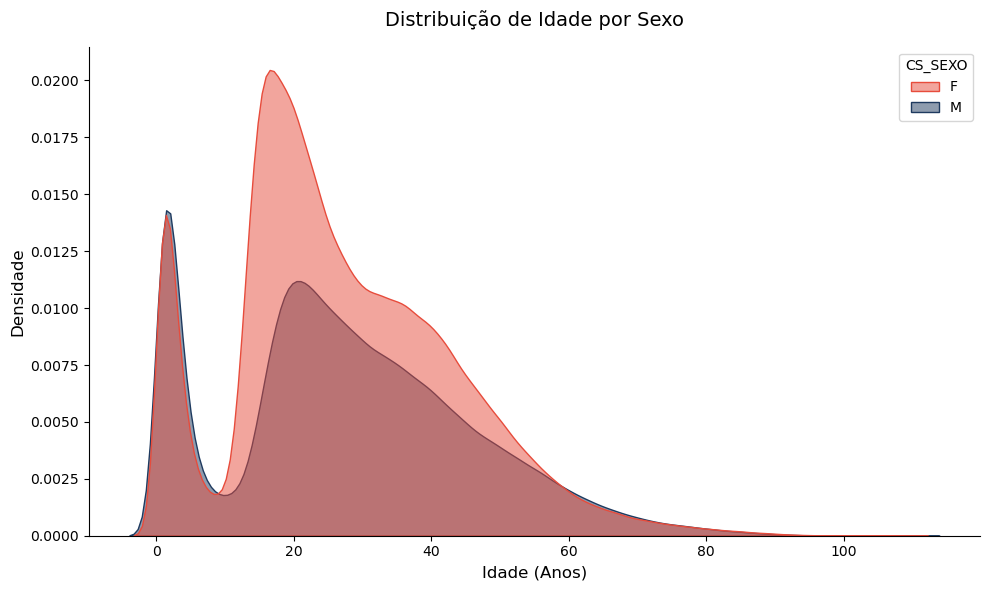

In [25]:
# Filtra apenas os sexos M e F no dataframe limpo
df_sexo = df[df['CS_SEXO'].isin(['M', 'F'])]

plt.figure(figsize=(10, 6))

# Plotagem da densidade
sns.kdeplot(
    data=df_sexo, 
    x='IDADE_ANOS', 
    hue='CS_SEXO', 
    fill=True, 
    palette={'M': '#1E3A5F', 'F': '#e74c3c'}, 
    alpha=0.5
)

# Estética e rótulos
plt.title('Distribuição de Idade por Sexo', fontsize=14, pad=15)
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Densidade', fontsize=12)

sns.despine()
plt.tight_layout()

# Salvando a imagem individual
#plt.savefig('distribuicao_idade_sexo.png', dpi=300, bbox_inches='tight')

plt.show()

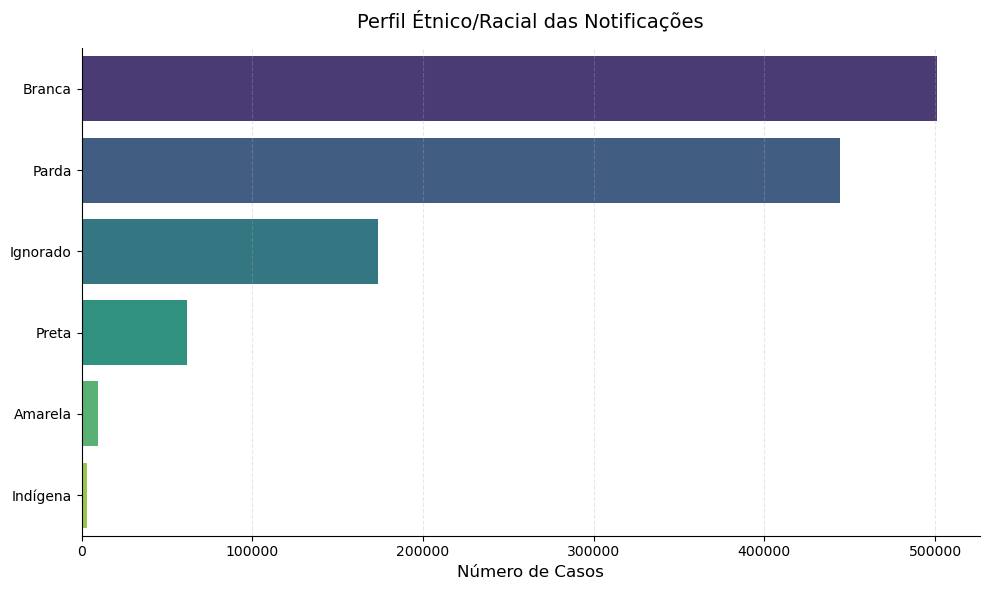

In [26]:
plt.figure(figsize=(10, 6))

# Calcula a ordem das categorias da maior para a menor
ordem_raca = df['CS_RACA_DESC'].value_counts().index

# Plotagem das barras horizontais (hue adicionado para evitar warnings)
sns.countplot(
    data=df, 
    y='CS_RACA_DESC', 
    order=ordem_raca, 
    hue='CS_RACA_DESC',
    palette='viridis',
    legend=False
)

# Estética e rótulos
plt.title('Perfil Étnico/Racial das Notificações', fontsize=14, pad=15)
plt.xlabel('Número de Casos', fontsize=12)
plt.ylabel('', fontsize=12) # Deixei vazio pois os nomes das raças já explicam o eixo

# Adicionando um grid vertical suave para facilitar a leitura dos números
plt.grid(axis='x', alpha=0.3, linestyle='--')
sns.despine()
plt.tight_layout()

# Salvando a imagem individual
#plt.savefig('perfil_etnico.png', dpi=300, bbox_inches='tight')

plt.show()

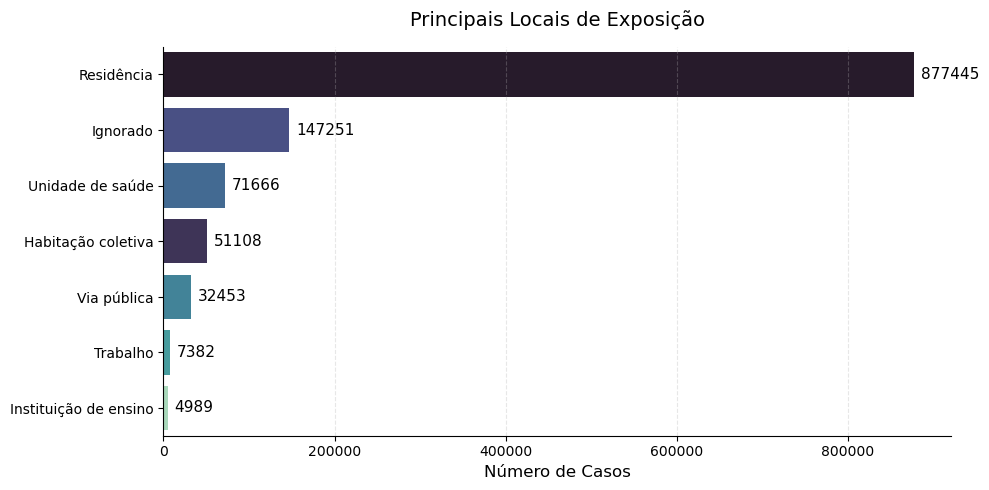

In [27]:
plt.figure(figsize=(10, 5))

ordem_local = df['LOC_EXPO_DESC'].value_counts().head(7).index

ax = sns.countplot(
    data=df, 
    y='LOC_EXPO_DESC', 
    order=ordem_local, 
    hue='LOC_EXPO_DESC',
    palette='mako',
    legend=False
)

plt.title('Principais Locais de Exposição', fontsize=14, pad=15)
plt.xlabel('Número de Casos', fontsize=12)
plt.ylabel('', fontsize=12)

# Adiciona os números no final de cada barra de forma limpa
for i in ax.containers: 
    ax.bar_label(i, padding=5, fmt='%d', fontsize=11)

sns.despine()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

#plt.savefig('locais_exposicao.png', dpi=300, bbox_inches='tight')
plt.show()

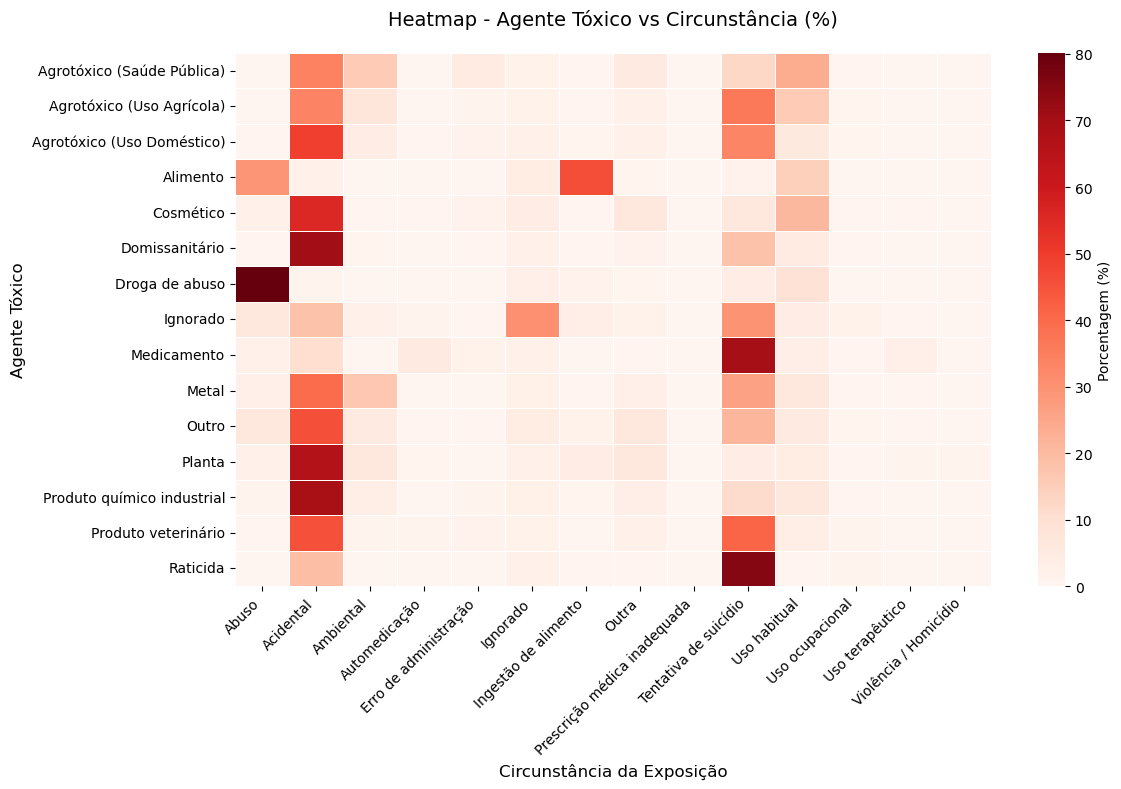

In [28]:
plt.figure(figsize=(12, 8))

crosstab_agente_circ = pd.crosstab(
    df['AGENTE_TOX_DESC'], 
    df['CIRCUNSTAN_DESC'], 
    normalize='index'
) * 100

sns.heatmap(
    crosstab_agente_circ, 
    cmap='Reds', 
    annot=False, 
    linewidths=.5,
    cbar_kws={'label': 'Porcentagem (%)'} 
)

plt.title('Heatmap - Agente Tóxico vs Circunstância (%)', fontsize=14, pad=20)
plt.xlabel('Circunstância da Exposição', fontsize=12)
plt.ylabel('Agente Tóxico', fontsize=12)

# 3. Rotaciona as legendas do eixo X para não ficarem sobrepostas
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
#plt.savefig('heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

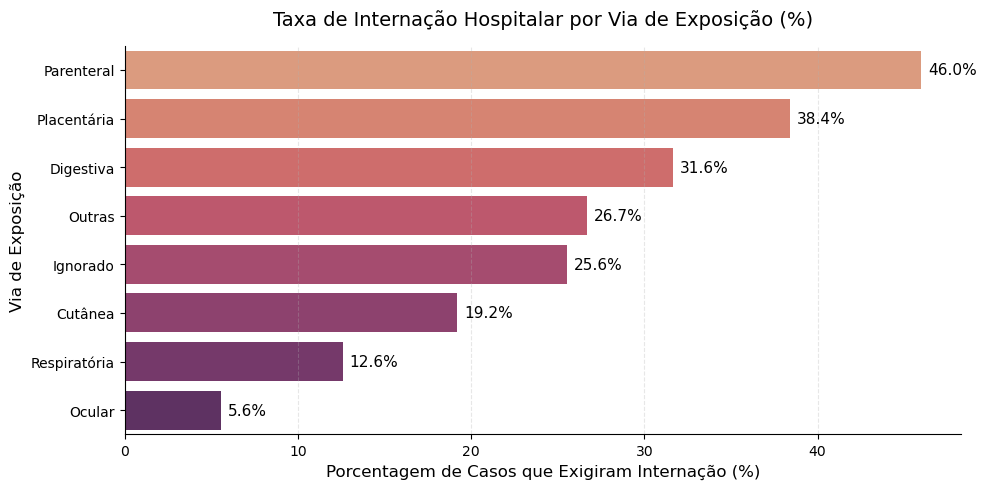

In [ ]:
plt.figure(figsize=(10, 5))

taxa_internacao_via = (df.groupby('VIA_1_DESC')['INTERNADO'].mean() * 100).sort_values(ascending=False)

ax = sns.barplot(
    x=taxa_internacao_via.values, 
    y=taxa_internacao_via.index, 
    hue=taxa_internacao_via.index,
    palette='flare',
    legend=False
)

plt.title('Taxa de Internação Hospitalar por Via de Exposição (%)', fontsize=14, pad=15)
plt.xlabel('Porcentagem de Casos que Exigiram Internação (%)', fontsize=12)
plt.ylabel('Via de Exposição', fontsize=12)

for i in ax.containers: 
    ax.bar_label(i, fmt='%.1f%%', padding=5, fontsize=11)

sns.despine()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

#plt.savefig('taxa_internacao_exposicao.png', dpi=300, bbox_inches='tight')
plt.show()

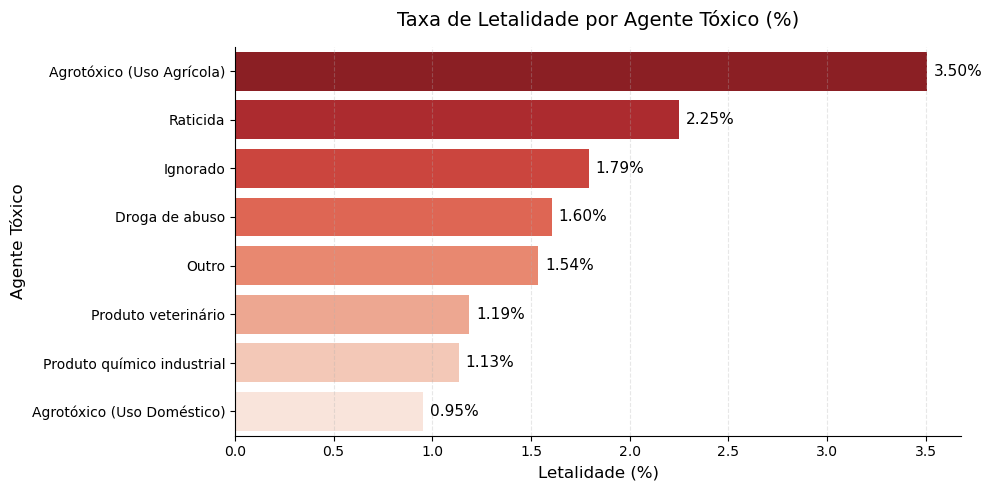

In [30]:
total_agente = df['AGENTE_TOX_DESC'].value_counts()
obitos_agente = df[df['EVOLUCAO_DESC'] == 'Óbito por Intoxicação Exógena']['AGENTE_TOX_DESC'].value_counts()

# Calcula a porcentagem, preenche nulos com 0 e pega os 8 mais letais
taxa_letalidade = (obitos_agente / total_agente * 100).fillna(0).sort_values(ascending=False).head(8)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    x=taxa_letalidade.values, 
    y=taxa_letalidade.index, 
    hue=taxa_letalidade.index,
    palette='Reds_r', 
    legend=False
)

plt.title('Taxa de Letalidade por Agente Tóxico (%)', fontsize=14, pad=15)
plt.xlabel('Letalidade (%)', fontsize=12)
plt.ylabel('Agente Tóxico', fontsize=12)

for i in ax.containers: 
    ax.bar_label(i, fmt='%.2f%%', padding=5, fontsize=11)

sns.despine()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

#plt.savefig('taxa_letalidade_agente.png', dpi=300, bbox_inches='tight')
plt.show()

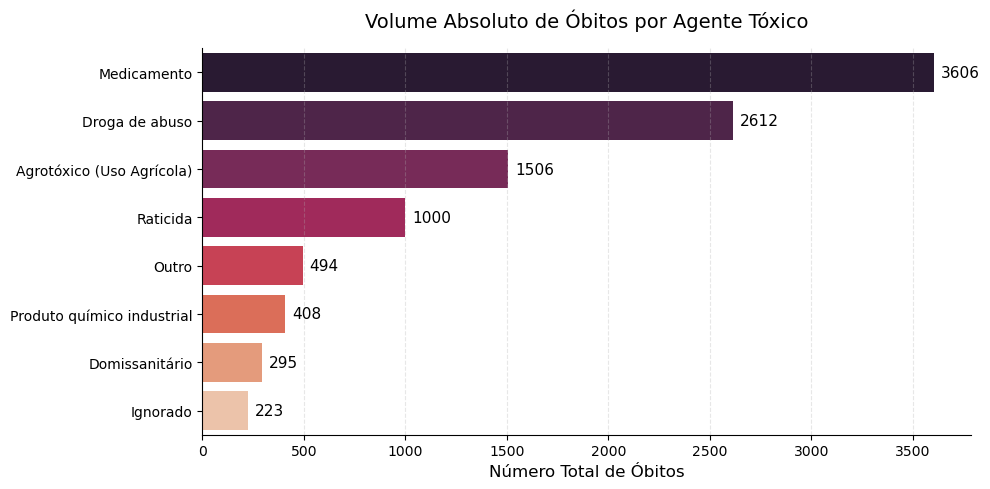

In [31]:
plt.figure(figsize=(10, 5))

# Pega os 8 agentes que mais causaram óbitos em números totais
top_obitos_absolutos = obitos_agente.sort_values(ascending=False).head(8)

ax = sns.barplot(
    x=top_obitos_absolutos.values, 
    y=top_obitos_absolutos.index, 
    hue=top_obitos_absolutos.index,
    palette='rocket', # Paleta escura para contraste com a anterior
    legend=False
)

plt.title('Volume Absoluto de Óbitos por Agente Tóxico', fontsize=14, pad=15)
plt.xlabel('Número Total de Óbitos', fontsize=12)
plt.ylabel('', fontsize=12) # Omitido pois o rótulo Y já deixa claro

# Adiciona os números absolutos (inteiros) nas barras
for i in ax.containers: 
    ax.bar_label(i, fmt='%d', padding=5, fontsize=11)

sns.despine()
plt.grid(axis='x', alpha=0.3, linestyle='--')
plt.tight_layout()

#plt.savefig('obitos_por_agente.png', dpi=300, bbox_inches='tight')
plt.show()